# Итоговое сравнение алгоритмов

Собираем метрики всех лабораторных из `results/results.jsonl` и сравниваем
модели в рамках каждой задачи. Отдельно — с какими оговорками эти цифры
можно интерпретировать.

In [1]:
# --- общая подготовка: путь к корню репозитория, импорт своих модулей ---
import sys
from pathlib import Path

# корень репозитория ищем вверх по дереву по маркеру src/ — ноутбук можно
# запускать из своей папки или из корня
ROOT = Path.cwd()
while not (ROOT / "src").exists() and ROOT.parent != ROOT:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.prep import StandardScaler, time_split
from src import metrics

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (7.5, 4)
plt.rcParams["axes.grid"] = True

In [2]:
# --- данные: панели MOEX и хронологическое разбиение ---
shares = pd.read_csv(ROOT / "data/processed/shares_features.csv", parse_dates=["date"])
bonds = pd.read_csv(ROOT / "data/processed/bonds_features.csv", parse_dates=["date"])

SHARE_FEATS = [
    "ret_1", "ret_2", "ret_3", "ret_5", "ret_10", "ret_20",      # лаги доходности
    "vol_5", "vol_20",                                            # волатильность
    "ma_ratio_5", "ma_ratio_20",                                  # отклонение от средних
    "hl_range", "oc_range",                                       # диапазон дня
    "vol_rel", "val_rel", "trd_rel",                              # относительные объёмы
    "rsi_14", "weekday", "month", "market_ret_1",                 # RSI, календарь, рынок
]
BOND_FEATS = [
    "YIELDCLOSE", "dyield_1", "dyield_5", "dyield_20",            # уровень и изменения доходности
    "ret_1", "ret_5", "ret_20", "vol_20",                         # цена и волатильность
    "DURATION", "COUPONPERCENT", "years_to_mat",                  # параметры выпуска
    "val_rel", "trd_rel", "price_to_face", "is_ofz",              # ликвидность, ОФЗ
]

# обучение — прошлое, тест — будущее; перемешивать нельзя, иначе утечка из будущего
sh_tr, sh_te = time_split(shares, split_date="2025-01-01")
bd_tr, bd_te = time_split(bonds, split_date="2025-10-01")

Xc_tr, yc_tr = sh_tr[SHARE_FEATS].to_numpy("float32"), sh_tr["target_up"].to_numpy()
Xc_te, yc_te = sh_te[SHARE_FEATS].to_numpy("float32"), sh_te["target_up"].to_numpy()
Xr_tr, yr_tr = bd_tr[BOND_FEATS].to_numpy("float32"), bd_tr["target_next_yield"].to_numpy()
Xr_te, yr_te = bd_te[BOND_FEATS].to_numpy("float32"), bd_te["target_next_yield"].to_numpy()

# масштабирование обучаем только на трейне
sc_c, sc_r = StandardScaler().fit(Xc_tr), StandardScaler().fit(Xr_tr)
Xc_tr_s, Xc_te_s = sc_c.transform(Xc_tr), sc_c.transform(Xc_te)
Xr_tr_s, Xr_te_s = sc_r.transform(Xr_tr), sc_r.transform(Xr_te)

print(f"акции:     {len(sh_tr):,} обучение / {len(sh_te):,} тест, признаков {len(SHARE_FEATS)}")
print(f"облигации: {len(bd_tr):,} обучение / {len(bd_te):,} тест, признаков {len(BOND_FEATS)}")
print("доля роста в тесте:", round(yc_te.mean(), 4))

акции:     37,154 обучение / 22,468 тест, признаков 19
облигации: 8,459 обучение / 10,468 тест, признаков 15
доля роста в тесте: 0.4633


In [3]:
# --- все сохранённые результаты ---
RESULTS = ROOT / "results"
RESULT_FILE = RESULTS / "results.jsonl"
res = pd.read_json(RESULT_FILE, lines=True)
res = res.drop_duplicates(subset=["lab", "task", "model"], keep="last")
print(res.groupby("task").size())
res

task
classification    12
regression        12
dtype: int64


,lab,task,model,accuracy,precision,recall,f1,tp,fp,tn,fn,roc_auc,rmse,mae,r2
0,lab2_linear,classification,sklearn logreg,0.5111,0.4638,0.3534,0.4012,3679.0,4253.0,7805.0,6731.0,0.4922,NaN,NaN,NaN
1,lab2_linear,regression,sklearn ridge,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.9047,0.4215,0.9861
2,lab2_linear,regression,naive (yield_t),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.8877,0.3992,0.9866
3,lab2_linear,classification,my logreg GD,0.5112,0.4638,0.3524,0.4005,3668.0,4241.0,7817.0,6742.0,0.4923,NaN,NaN,NaN
4,lab2_linear,regression,my ridge (closed form),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.9047,0.4215,0.9861
5,lab2_linear,regression,my linear GD,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.9061,0.4237,0.9861
6,lab2_linear,classification,"my logreg, short feature set",0.5118,0.4643,0.3488,0.3983,3631.0,4190.0,7868.0,6779.0,0.4916,NaN,NaN,NaN
7,lab3_tree,classification,sklearn tree,0.5241,0.4835,0.3969,0.4360,4132.0,4414.0,7644.0,6278.0,0.5139,NaN,NaN,NaN
8,lab3_tree,regression,sklearn tree,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.1334,0.5652,0.9782
9,lab3_tree,classification,my tree,0.5241,0.4835,0.3969,0.4360,4132.0,4414.0,7644.0,6278.0,0.5138,NaN,NaN,NaN


## Классификация: направление цены на следующий день

In [4]:
# --- таблица метрик: классификация ---
clf_cols = ["lab", "model", "accuracy", "precision", "recall", "f1", "roc_auc"]
clf = res[res.task == "classification"][clf_cols].sort_values("roc_auc", ascending=False)
clf.reset_index(drop=True)

,lab,model,accuracy,precision,recall,f1,roc_auc
0,lab5_gbm,sklearn GBM,0.5433,0.5097,0.3724,0.4304,0.5367
1,lab5_gbm,my GBM,0.5381,0.5022,0.3696,0.4258,0.5339
2,lab4_rf,sklearn RF,0.5389,0.5038,0.3220,0.3929,0.5322
3,lab4_rf,my RF,0.5377,0.5017,0.3325,0.3999,0.5276
4,lab3_tree,sklearn tree,0.5241,0.4835,0.3969,0.4360,0.5139
5,lab3_tree,my tree,0.5241,0.4835,0.3969,0.4360,0.5138
6,lab1_knn,"my KNN (k=25, scaled)",0.5105,0.4698,0.4400,0.4544,0.5090
7,lab1_knn,sklearn KNN,0.5078,0.4674,0.4473,0.4571,0.5049
8,lab1_knn,my KNN,0.5078,0.4674,0.4473,0.4571,0.5049
9,lab2_linear,my logreg GD,0.5112,0.4638,0.3524,0.4005,0.4923


In [5]:
# --- тривиальные бейзлайны классификации: ориентир для accuracy ---
print(f"доля роста в тесте: {yc_te.mean():.4f}")
print(f"константа «вниз»:   accuracy={max(yc_te.mean(), 1 - yc_te.mean()):.4f}")
print(f"константа «вверх»:  accuracy={min(yc_te.mean(), 1 - yc_te.mean()):.4f}")


доля роста в тесте: 0.4633
константа «вниз»:   accuracy=0.5367
константа «вверх»:  accuracy=0.4633


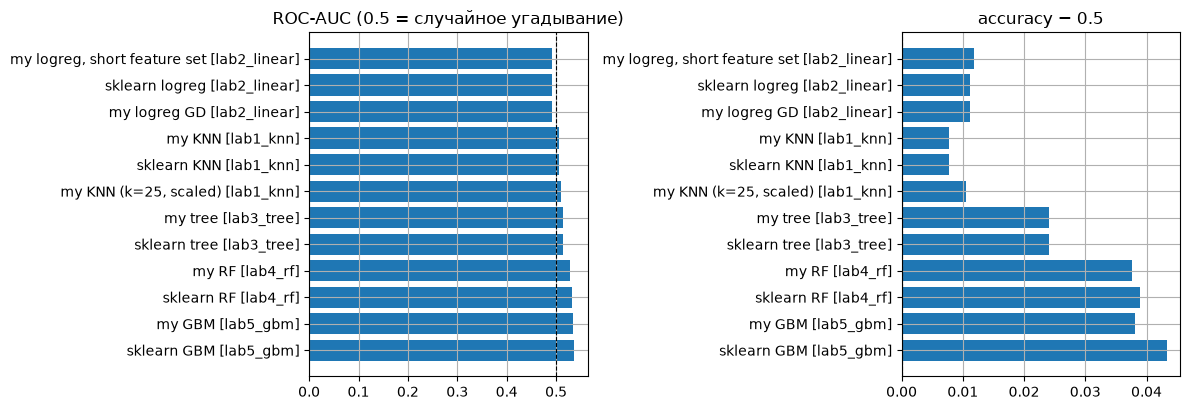

In [6]:
# --- график: ROC-AUC и accuracy по моделям ---
top = clf.dropna(subset=["roc_auc"]).head(12)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].barh(top.model + " [" + top.lab + "]", top.roc_auc)
ax[0].axvline(0.5, color="k", ls="--", lw=0.8); ax[0].set_title("ROC-AUC (0.5 = случайное угадывание)")
ax[1].barh(top.model + " [" + top.lab + "]", top.accuracy - 0.5)
ax[1].axvline(0, color="k", ls="--", lw=0.8); ax[1].set_title("accuracy − 0.5")
plt.tight_layout(); plt.show()

## Регрессия: доходность облигации на следующий день

In [7]:
# --- таблица метрик: регрессия ---
reg_cols = ["lab", "model", "rmse", "mae", "r2"]
reg = res[res.task == "regression"][reg_cols].sort_values("rmse")
reg.reset_index(drop=True)

,lab,model,rmse,mae,r2
0,lab2_linear,naive (yield_t),0.8877,0.3992,0.9866
1,lab2_linear,sklearn ridge,0.9047,0.4215,0.9861
2,lab2_linear,my ridge (closed form),0.9047,0.4215,0.9861
3,lab2_linear,my linear GD,0.9061,0.4237,0.9861
4,lab5_gbm,my GBM,0.9149,0.4618,0.9858
5,lab5_gbm,sklearn GBM,1.0189,0.4827,0.9824
6,lab3_tree,sklearn tree,1.1334,0.5652,0.9782
7,lab3_tree,my tree,1.1336,0.5653,0.9782
8,lab4_rf,sklearn RF,1.5423,0.8150,0.9596
9,lab4_rf,my RF,1.6333,0.9116,0.9547


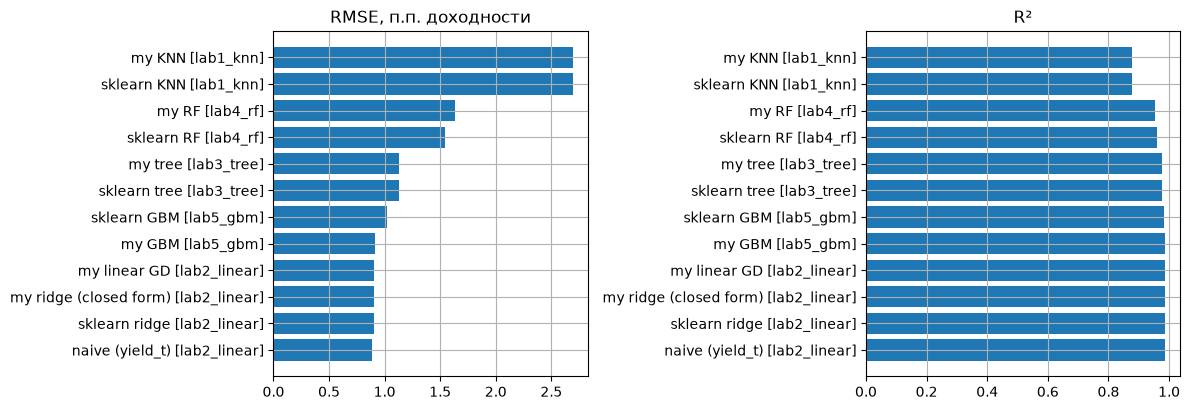

In [8]:
# --- график: RMSE по моделям (меньше — лучше) ---
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].barh(reg.model + " [" + reg.lab + "]", reg.rmse); ax[0].set_title("RMSE, п.п. доходности")
ax[1].barh(reg.model + " [" + reg.lab + "]", reg.r2); ax[1].set_title("R²")
plt.tight_layout(); plt.show()

## Сводная таблица

| Задача | Метрика | Победитель | Значение |
|---|---|---|---|
| Классификация | accuracy | sklearn GBM (ЛР-5) | 0.5433 |
| Классификация | ROC-AUC | sklearn GBM (ЛР-5) | 0.5367 |
| Регрессия | RMSE | наивный прогноз «завтра = сегодня» | 0.8877 |
| Регрессия | RMSE среди моделей | ridge (ЛР-2) | 0.9047 |

**Главная оговорка по accuracy.** В тесте доля роста всего 0.4633, поэтому
константный прогноз «вниз» уже даёт accuracy 0.5367. Лучшая модель (бустинг,
0.5433) обходит его лишь на 0.7 п.п. По ROC-AUC картина честнее: 0.5367 у
бустинга против 0.5 у монетки — сигнал есть, но он очень слабый.

**Почему классификация такая слабая.** Дневное направление цены акции —
почти мартингал: прошлые доходности дают исчезающе малую информацию о будущих.
Все пять семейств моделей упираются в 0.508–0.543 accuracy и 0.492–0.537 AUC,
то есть в «потолок данных». Это ожидаемый и содержательный результат:
он показывает, что разница между алгоритмами меньше, чем шум.

**Почему регрессия выглядит хорошей.** Доходность к погашению облигации —
медленно меняющийся уровень; «завтра ≈ сегодня» уже даёт R² ≈ 0.98.
Деревья и лес здесь проигрывают линейным моделям и бустингу, потому что
не умеют экстраполировать уровень за пределы обучающего диапазона
(а тест — целиком будущий период с другим уровнем ставок).

## Выводы по всем лабораторным

1. По классификации ансамбли (бустинг 0.543, лес 0.539) дают плюс к accuracy
   относительно линейной модели и KNN (0.508–0.512); чистая линейная модель
   по AUC даже хуже монетки (0.492) — сигнал нелинейный, но слабый.
   По регрессии расклад иной: наивный прогноз «завтра = сегодня» лучше любой
   модели (RMSE 0.888), среди моделей — линейные (0.905) ≈ бустинг (0.915) >
   дерево (1.13) > лес (1.54) > KNN (2.69).
2. Свои реализации совпадают со sklearn на контрольных сравнениях, значит
   все различия в цифрах — свойства алгоритмов, а не баги.
3. Главный вывод для финансовой задачи: **признаки важнее алгоритма**.
   Пять разных семейств на одном наборе признаков укладываются в 3.5 п.п.
   accuracy и 4.5 п.п. AUC, тогда как в регрессии наивный прогноз обгоняет
   худшую модель (KNN) более чем втрое (0.888 против 2.69).
4. Ограничение работы: гиперпараметры подбирались по тесту (демонстрационный
   режим), строгий эксперимент требует отдельного валидационного периода.
